In [1]:
"hi"

'hi'

In [2]:
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
dfi = pd.read_csv(r"C:\Users\DELL\Desktop\python imarticus\Shankhan@7\insurance.csv")
dfi

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


In [4]:
### feature selection no column drop because evrything is important

In [5]:
dfi.isna().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [6]:
dfi.dtypes

age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
charges     float64
dtype: object

In [7]:
dfi["sex"].unique()

<StringArray>
['female', 'male']
Length: 2, dtype: str

In [8]:
dfi['sex'].value_counts()

sex
male      676
female    662
Name: count, dtype: int64

In [9]:
dfi["smoker"].unique()
dfi["smoker"].value_counts()

smoker
no     1064
yes     274
Name: count, dtype: int64

In [10]:
dfi["region"].unique()
dfi["region"].value_counts()

region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64

In [11]:
dfi.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


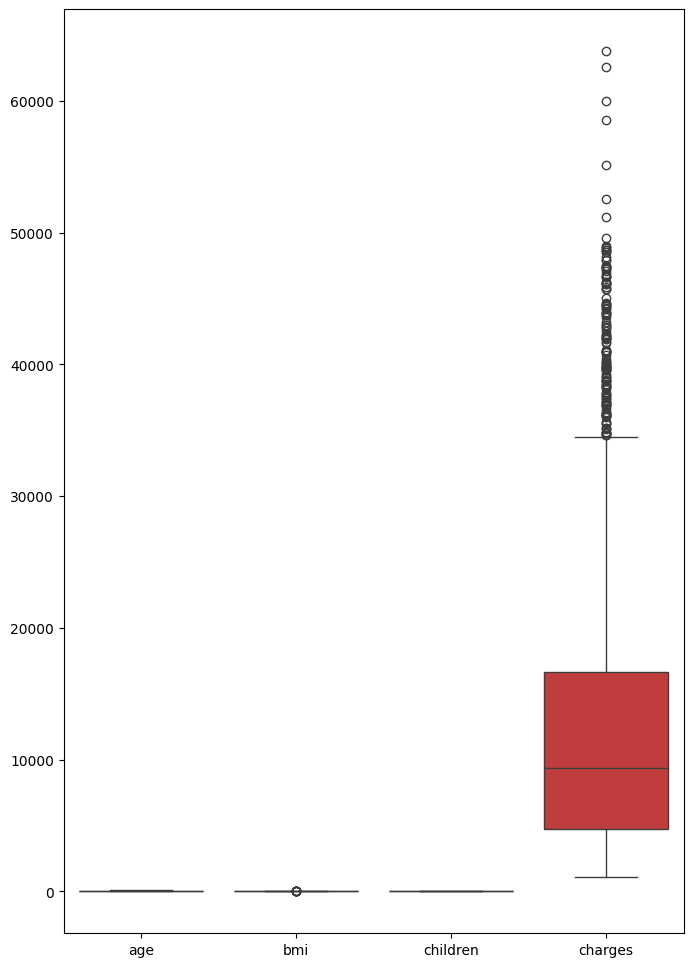

In [12]:
plt.figure(figsize=(8, 12))
sns.boxplot(dfi)

dfi.describe()

In [13]:
## BMI error
q1 = dfi["bmi"].quantile(0.25)
q3 = dfi["bmi"].quantile(0.75)
iqr = q3-q1
lower = q1 - (1.5*iqr)
upper = q3 + (1.5*iqr)


dfi[(dfi["bmi"]<lower) | (dfi["bmi"] >upper)].count()


age         9
sex         9
bmi         9
children    9
smoker      9
region      9
charges     9
dtype: int64

In [14]:
dfi["bmi"].map(lambda x : lower if x<lower else upper if x>upper else x)

0       27.900
1       33.770
2       33.000
3       22.705
4       28.880
         ...  
1333    30.970
1334    31.920
1335    36.850
1336    25.800
1337    29.070
Name: bmi, Length: 1338, dtype: float64

In [15]:
dfi["bmi"] = dfi["bmi"].map(lambda x : lower if x<lower else upper if x>upper else x)
dfi["bmi"].count()

np.int64(1338)

In [16]:
dfi["sex"].unique()

<StringArray>
['female', 'male']
Length: 2, dtype: str

In [17]:
dfi["smoker"].unique()

<StringArray>
['yes', 'no']
Length: 2, dtype: str

In [18]:
dfi["region"].unique()

<StringArray>
['southwest', 'southeast', 'northwest', 'northeast']
Length: 4, dtype: str

In [19]:
dfi = pd.get_dummies(dfi)

dfi.replace({True: 1, False: 0}, inplace=True)

,age,bmi,children,charges,sex_female,sex_male,smoker_no,smoker_yes,region_northeast,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,1,0,0,1,0,0,0,1
1,18,33.770,1,1725.55230,0,1,1,0,0,0,1,0
2,28,33.000,3,4449.46200,0,1,1,0,0,0,1,0
3,33,22.705,0,21984.47061,0,1,1,0,0,1,0,0
4,32,28.880,0,3866.85520,0,1,1,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
1333,50,30.970,3,10600.54830,0,1,1,0,0,1,0,0
1334,18,31.920,0,2205.98080,1,0,1,0,1,0,0,0
1335,18,36.850,0,1629.83350,1,0,1,0,0,0,1,0
1336,21,25.800,0,2007.94500,1,0,1,0,0,0,0,1


In [20]:
x = dfi.drop("charges",axis=1)
x.shape

(1338, 11)

In [21]:
y = dfi["charges"]
y

0       16884.92400
1        1725.55230
2        4449.46200
3       21984.47061
4        3866.85520
           ...     
1333    10600.54830
1334     2205.98080
1335     1629.83350
1336     2007.94500
1337    29141.36030
Name: charges, Length: 1338, dtype: float64

In [22]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.20,random_state=367)
score1=[]
# for i in range(500):
#     X_train1,X_test1,y_train1,y_test1 = train_test_split(x,y,test_size=0.20,random_state=i)
#     lr1 = LinearRegression()
#     lr1.fit(X_train1,y_train1)
#     s1 = lr1.score(X_test1,y_test1)
#     score1.append(s1)
# mx = max(score1)
# score1.index(mx)

In [23]:
## LINEAR REGRESSION
from sklearn.linear_model import LinearRegression
lr = LinearRegression()
lr


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [24]:
lr.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [25]:
lr.coef_

array([   256.00596074,    332.43477907,    517.17194175,    112.53872572,
         -112.53872572, -11739.62306787,  11739.62306787,    528.24141779,
          190.76320011,   -411.08627977,   -307.91833813])

In [26]:
lr.intercept_

np.float64(-489.45815417199265)

In [27]:
lr.score(x_test,y_test)

0.8331309092720207

## Auto ML

In [ ]:
# auto ml = 

In [29]:
from sklearn.tree import DecisionTreeRegressor

from sklearn.ensemble import RandomForestRegressor

from sklearn.svm import SVR

from sklearn.ensemble import AdaBoostRegressor

from sklearn.neighbors import KNeighborsRegressor


In [30]:
dt1 = DecisionTreeRegressor()
rfc1 = RandomForestRegressor()
svm1 = SVR()
ada1 = AdaBoostRegressor()
knn1 = KNeighborsRegressor()

In [31]:
models_lst = [dt1,rfc1,svm1,ada1,knn1,lr]


In [32]:
models_lst

[DecisionTreeRegressor(),
 RandomForestRegressor(),
 SVR(),
 AdaBoostRegressor(),
 KNeighborsRegressor(),
 LinearRegression()]

In [33]:
import time
for m in models_lst:
    print(m)
    time.sleep(1)

DecisionTreeRegressor()
RandomForestRegressor()
SVR()
AdaBoostRegressor()
KNeighborsRegressor()
LinearRegression()


In [34]:
for m in models_lst:
    m.fit(x_train,y_train)
    s = m.score(x_test,y_test)
    print(m,"==>",s)
    time.sleep(1)

DecisionTreeRegressor() ==> 0.7083058511692737
RandomForestRegressor() ==> 0.8909375211850437
SVR() ==> -0.11556441633139536
AdaBoostRegressor() ==> 0.847342664624283
KNeighborsRegressor() ==> 0.25934535949044435
LinearRegression() ==> 0.8331309092720207


## Cross validation

In [45]:
from sklearn.model_selection import cross_val_score
rfc2 = RandomForestRegressor()
scores =cross_val_score(rfc2,x,y,cv=20,n_jobs=-1)



In [46]:
scores
scores.mean()

np.float64(0.8287726570084445)

In [47]:
rfc3 = RandomForestRegressor()
scores =cross_val_score(rfc3,x,y,cv=20,n_jobs=-1)


In [48]:
scores.mean()

np.float64(0.8306316390746049)

In [55]:
# for m in models_lst:
#     m.fit(x_train,y_train)
#     s = m.score(x_test,y_test)
#     print(m,"==>",s)
#     time.sleep(1)
scores = []

for m in models_lst:
    sc = cross_val_score(m,x,y,cv=10,n_jobs=-1)
    sc1 = sc.mean()
    scores.append(sc1)
    



In [58]:
print(scores)
models_lst

[np.float64(0.6827741104563763), np.float64(0.838248123330119), np.float64(-0.10503251769855412), np.float64(0.824411752415053), np.float64(0.27526094415071584), np.float64(0.7445706481144528)]


[DecisionTreeRegressor(),
 RandomForestRegressor(),
 SVR(),
 AdaBoostRegressor(),
 KNeighborsRegressor(),
 LinearRegression()]

## prediction

In [59]:
lr

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [60]:
dfi.head()

,age,bmi,children,charges,sex_female,sex_male,smoker_no,smoker_yes,region_northeast,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,1,0,0,1,0,0,0,1
1,18,33.770,1,1725.55230,0,1,1,0,0,0,1,0
2,28,33.000,3,4449.46200,0,1,1,0,0,0,1,0
3,33,22.705,0,21984.47061,0,1,1,0,0,1,0,0
4,32,28.880,0,3866.85520,0,1,1,0,0,1,0,0


In [61]:
x.head()

,age,bmi,children,sex_female,sex_male,smoker_no,smoker_yes,region_northeast,region_northwest,region_southeast,region_southwest
0,19,27.900,0,1,0,0,1,0,0,0,1
1,18,33.770,1,0,1,1,0,0,0,1,0
2,28,33.000,3,0,1,1,0,0,0,1,0
3,33,22.705,0,0,1,1,0,0,1,0,0
4,32,28.880,0,0,1,1,0,0,1,0,0


In [62]:
y.head()

0    16884.92400
1     1725.55230
2     4449.46200
3    21984.47061
4     3866.85520
Name: charges, dtype: float64

In [68]:
lr.predict([[19,27.900,0,1,0,0,1,0,0,0,1]])

c:\Users\DELL\Desktop\python imarticus\.venv\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([25193.82889138])

In [66]:
dfi

,age,bmi,children,charges,sex_female,sex_male,smoker_no,smoker_yes,region_northeast,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,1,0,0,1,0,0,0,1
1,18,33.770,1,1725.55230,0,1,1,0,0,0,1,0
2,28,33.000,3,4449.46200,0,1,1,0,0,0,1,0
3,33,22.705,0,21984.47061,0,1,1,0,0,1,0,0
4,32,28.880,0,3866.85520,0,1,1,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
1333,50,30.970,3,10600.54830,0,1,1,0,0,1,0,0
1334,18,31.920,0,2205.98080,1,0,1,0,1,0,0,0
1335,18,36.850,0,1629.83350,1,0,1,0,0,0,1,0
1336,21,25.800,0,2007.94500,1,0,1,0,0,0,0,1


In [69]:
18/5


3.6